## Análisis de campaña promocional de marketing

### 📍 Objetivo: identificar segmentos de clientes clave para desarrollar una estrategia de marketing data-driven.

### 📈 El contexto:
El equipo de marketing ha realizado una prueba enviando diferentes combinaciones de ofertas promocionales a los miembros existentes del programa de recompensas. Ahora que el periodo de 30 días de la prueba ha concluido, tu tarea es identificar los segmentos clave de clientes y desarrollar una estrategia basada en datos para los futuros mensajes y la segmentación promocional.

Los resultados deben resumirse en un informe que será presentado al Director de Marketing (CMO).

### 💡 Ideas de insights a obtener:
- Big numbers:
    - Total Customers
    - Total offers received
    - Total revenue
    - Total Reward
    - Total offers viewd + view rate
    - Total offers completed + completion rate
    - Offers-related revenue + percentage of the total revenue
- Customer segmentation:
    - Age group
    - Income group
    - Gender
    - Memberships across years
- Funnel análisis by age group, income group and gender
    - Clicks
    - Rewards and revenue

In [50]:
import pandas as pd
import ast
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [43]:
customers = pd.read_csv('/Users/albavicenteolmo/Downloads/Cafe+Rewards+Offers/customers.csv')
offers = pd.read_csv('/Users/albavicenteolmo/Downloads/Cafe+Rewards+Offers/offers.csv')
events = pd.read_csv('/Users/albavicenteolmo/Downloads/Cafe+Rewards+Offers/events.csv')

In [34]:
print('customers: ', customers.shape)
print('offers: ', offers.shape)
print('events: ', events.shape)

customers:  (17000, 5)
offers:  (10, 6)
events:  (306534, 4)


In [8]:
print('Customers: ', customers.columns)
print('offers: ', offers.columns)
print('events: ', events.columns)

Customers:  Index(['customer_id', 'became_member_on', 'gender', 'age', 'income'], dtype='object')
offers:  Index(['offer_id', 'offer_type', 'difficulty', 'reward', 'duration',
       'channels'],
      dtype='object')
events:  Index(['customer_id', 'event', 'value', 'time'], dtype='object')


## 1. Analizamos las tablas de Customers y Offers, para entender la dimensionalidad

In [39]:
customers.head()

,customer_id,became_member_on,gender,age,income
0,68be06ca386d4c31939f3a4f0e3dd783,20170212,NaN,118,NaN
1,0610b486422d4921ae7d2bf64640c50b,20170715,F,55,112000.0
2,38fe809add3b4fcf9315a9694bb96ff5,20180712,NaN,118,NaN
3,78afa995795e4d85b5d9ceeca43f5fef,20170509,F,75,100000.0
4,a03223e636434f42ac4c3df47e8bac43,20170804,NaN,118,NaN


In [40]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       17000 non-null  object 
 1   became_member_on  17000 non-null  int64  
 2   gender            14825 non-null  object 
 3   age               17000 non-null  int64  
 4   income            14825 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 664.2+ KB


El campo "became_member_on" podríamos transformarlo a una fecha.

In [44]:
customers_cleaned = customers.copy()

In [45]:
# Probar a hacer el error!
customers_cleaned['became_member_on'] = pd.to_datetime(customers_cleaned['became_member_on'], format='%Y%m%d', errors='coerce')

In [46]:
customers_cleaned.head()

,customer_id,became_member_on,gender,age,income
0,68be06ca386d4c31939f3a4f0e3dd783,2017-02-12,NaN,118,NaN
1,0610b486422d4921ae7d2bf64640c50b,2017-07-15,F,55,112000.0
2,38fe809add3b4fcf9315a9694bb96ff5,2018-07-12,NaN,118,NaN
3,78afa995795e4d85b5d9ceeca43f5fef,2017-05-09,F,75,100000.0
4,a03223e636434f42ac4c3df47e8bac43,2017-08-04,NaN,118,NaN


In [47]:
# La clave de la tabla es customer_id, hay 17,000 diferentes
print(customers_cleaned.nunique())

customer_id         17000
became_member_on     1716
gender                  3
age                    85
income                 91
dtype: int64


In [204]:
#Hay bastantes nulls en el género y el income: habrá que valorar cómo hay que gestionarlos
(customers_cleaned.isnull().sum() / len(customers_cleaned))*100

customer_id          0.000000
became_member_on     0.000000
gender               0.000000
age                  0.000000
income              12.794118
dtype: float64

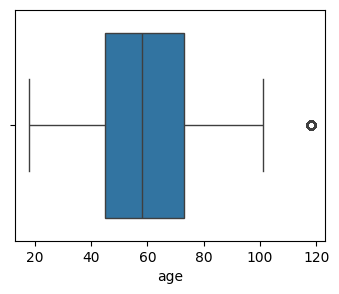

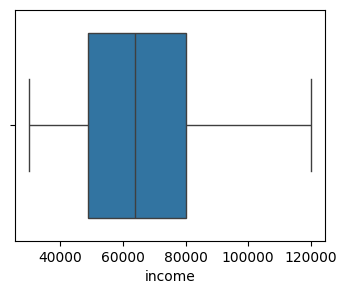

In [51]:
# Outliers
for c in customers_cleaned.select_dtypes(np.number).columns:
    plt.figure(figsize=(4, 3))
    sns.boxplot(data=customers_cleaned, x=c)
    plt.show()

In [58]:
#Gestionamos los outliers de la variable Age con el método IQR
Q1 = customers['age'].quantile(0.25)
Q3 = customers['age'].quantile(0.75)
IQR = Q3 - Q1

outliers_age = customers[(customers['age'] > (Q3 + 1.5*IQR)) | (customers['age'] < (Q1 - 1.5*IQR))]
print('Top Whisker: ', Q3 + 1.5*IQR)
print('Bottom Whisker: ', Q1 - 1.5*IQR)
print(outliers_age['age'].value_counts())

Top Whisker:  115.0
Bottom Whisker:  3.0
age
118    2175
Name: count, dtype: int64


Hay muchos outliers, ¿cómo los podemos gestionar?

<Axes: xlabel='age', ylabel='Count'>

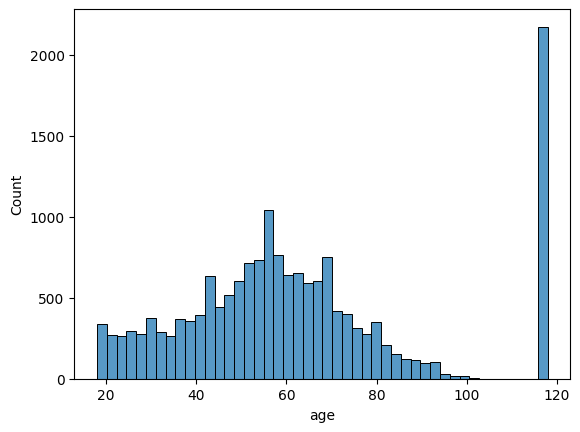

In [59]:
sns.histplot(data=customers, x='age')

In [61]:
#Imputamos la media o la mediana? -> los outliers hacen que la media se desplace hacia arriba
print('Mean: ', customers['age'].mean())
print('Median: ', customers['age'].median())

Mean:  62.53141176470588
Median:  58.0


In [63]:
#Reemplazamos con la mediana
#Opción 1:
customers['age'] = customers['age'].replace(118, customers['age'].median())

#Opción 2:
#customers['age'].loc[outliers_age, 'age'] = customers['age'].median()

<Axes: xlabel='age', ylabel='Count'>

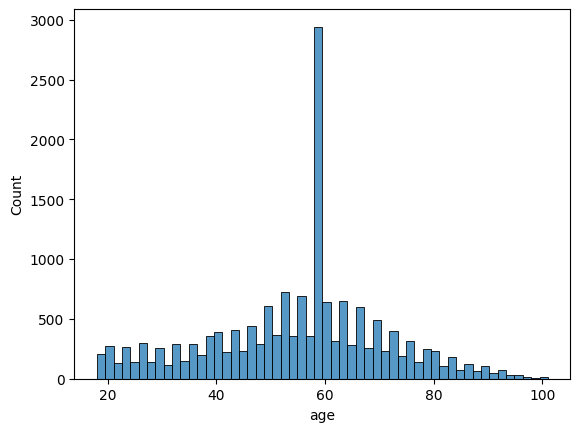

In [64]:
sns.histplot(data=customers, x='age')

In [67]:
#Outliers en la fecha?
customers_cleaned['became_member_on'].max()

Timestamp('2018-07-26 00:00:00')

In [192]:
#GESTIONAR NULLS EN GENDER E INCOME: pregunta importante: ¿puedo eliminar esas filas?
customers_cleaned['gender'].unique()

array([nan, 'F', 'M', 'O'], dtype=object)

In [193]:
# ¿Qué porcentaje de clientes no tienen género asociado?
customers_cleaned['gender'].isnull().sum() / len(customers_cleaned['gender'])

np.float64(0.12794117647058822)

In [197]:
# Asociamos los nulls a 'Unknown', que a lo mejor no tenemos que tener en cuenta en el futuro
customers_cleaned['gender'] = customers_cleaned['gender'].fillna('Unknown')

In [198]:
#Nulls en income
customers_cleaned['income'].isnull().sum() / len(customers_cleaned['income'])

np.float64(0.12794117647058822)

<Axes: xlabel='income', ylabel='Count'>

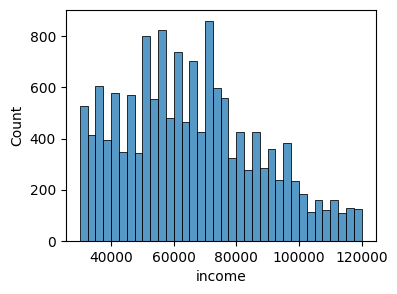

In [199]:
plt.figure(figsize=(4,3))
sns.histplot(data=customers_cleaned, x='income')

In [201]:
print(customers_cleaned['income'].min())
print(customers_cleaned['income'].max())

30000.0
120000.0


In [205]:
#Estrategias: como la distribución de ingresos es de tipo newgative skew, la media se ve muy alterada asi que elegimos la mediana
customers_cleaned['income'] = customers_cleaned['income'].fillna(customers_cleaned['income'].median())

In [206]:
customers_cleaned.isnull().sum()

customer_id         0
became_member_on    0
gender              0
age                 0
income              0
dtype: int64

#### Offers

In [65]:
#Ahora vamos a entender el dataframe de offers
offers.sample(5)

,offer_id,offer_type,difficulty,reward,duration,channels
5,2298d6c36e964ae4a3e7e9706d1fb8c2,discount,7,3,7,"['web', 'email', 'mobile', 'social']"
8,f19421c1d4aa40978ebb69ca19b0e20d,bogo,5,5,5,"['web', 'email', 'mobile', 'social']"
4,0b1e1539f2cc45b7b9fa7c272da2e1d7,discount,20,5,10,"['web', 'email']"
6,fafdcd668e3743c1bb461111dcafc2a4,discount,10,2,10,"['web', 'email', 'mobile', 'social']"
9,2906b810c7d4411798c6938adc9daaa5,discount,10,2,7,"['web', 'email', 'mobile']"


In [70]:
offers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   offer_id    10 non-null     object
 1   offer_type  10 non-null     object
 2   difficulty  10 non-null     int64 
 3   reward      10 non-null     int64 
 4   duration    10 non-null     int64 
 5   channels    10 non-null     object
dtypes: int64(3), object(3)
memory usage: 612.0+ bytes


In [73]:
#Vamos a entender los tipos de ofertas que hay
offers['offer_type'].value_counts()

offer_type
bogo             4
discount         4
informational    2
Name: count, dtype: int64

In [75]:
offers[offers['offer_type'] == 'bogo'].head()

,offer_id,offer_type,difficulty,reward,duration,channels
0,ae264e3637204a6fb9bb56bc8210ddfd,bogo,10,10,7,"['email', 'mobile', 'social']"
1,4d5c57ea9a6940dd891ad53e9dbe8da0,bogo,10,10,5,"['web', 'email', 'mobile', 'social']"
3,9b98b8c7a33c4b65b9aebfe6a799e6d9,bogo,5,5,7,"['web', 'email', 'mobile']"
8,f19421c1d4aa40978ebb69ca19b0e20d,bogo,5,5,5,"['web', 'email', 'mobile', 'social']"


<Axes: xlabel='difficulty'>

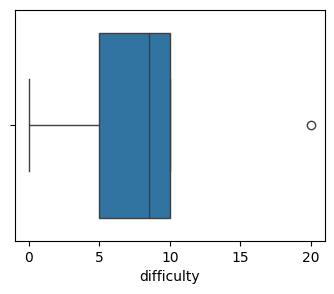

In [77]:
#Podemos ver si hay algún outlier pero lo más probable es que no
plt.figure(figsize=(4, 3))
sns.boxplot(data=offers, x='difficulty')

In [78]:
offers[offers['difficulty'] > 15]

,offer_id,offer_type,difficulty,reward,duration,channels
4,0b1e1539f2cc45b7b9fa7c272da2e1d7,discount,20,5,10,"['web', 'email']"


<Axes: xlabel='duration'>

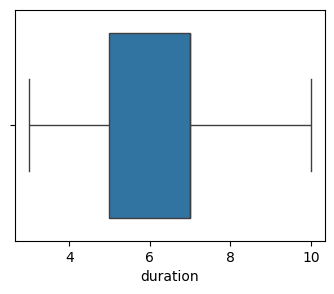

In [80]:
#Podemos ver si hay algún outlier pero lo más probable es que no
plt.figure(figsize=(4, 3))
sns.boxplot(data=offers, x='duration')

## 2. Entendemos la tabla de eventos
Para intentar entender los datos, profundizzamos un poco más en el df de eventos:

In [9]:
events.sample(10)

,customer_id,event,value,time
286506,f27e921ee8254022a84afa2c98fd0abd,transaction,{'amount': 30.45},636
195283,94bbb6006dbb49279728a9c0df4ac989,transaction,{'amount': 25.49},480
263854,592c5c82eacf47c7b989afcee87c604f,offer viewed,{'offer id': '2298d6c36e964ae4a3e7e9706d1fb8c2'},582
67602,f817370b73334e6692ea184342983684,offer completed,{'offer_id': 'f19421c1d4aa40978ebb69ca19b0e20d...,168
12390,f4e953ec3a484683935d8d42216fd11e,offer received,{'offer id': '2906b810c7d4411798c6938adc9daaa5'},0
14270,a67060333adb4e4aa700c015850e2002,offer viewed,{'offer id': '0b1e1539f2cc45b7b9fa7c272da2e1d7'},0
74317,cb294611652a4570ad79eb61cffd5e9b,offer viewed,{'offer id': 'ae264e3637204a6fb9bb56bc8210ddfd'},180
92784,cf61dbadb9f840d0bd8fd8ad7d3d26c8,transaction,{'amount': 0.68},240
203487,7f63df7e34f0450f81bdb65c3ab57295,offer received,{'offer id': 'fafdcd668e3743c1bb461111dcafc2a4'},504
217811,c4be80f0d24a408cbf2131603bb93b66,offer viewed,{'offer id': '2298d6c36e964ae4a3e7e9706d1fb8c2'},504


In [85]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 306534 entries, 0 to 306533
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   customer_id  306534 non-null  object
 1   event        306534 non-null  object
 2   value        306534 non-null  object
 3   time         306534 non-null  int64 
dtypes: int64(1), object(3)
memory usage: 9.4+ MB


In [84]:
events['event'].value_counts()

event
transaction        138953
offer received      76277
offer viewed        57725
offer completed     33579
Name: count, dtype: int64

In [83]:
#Vamos a entender qué está ocurriendo para un usuario que sabemos SI ha hecho un "offer completed"
events[events['customer_id'] == '9fa9ae8f57894cc9a3b8a9bbe0fc1b2f'].sort_values(by='time')

,customer_id,event,value,time
36,9fa9ae8f57894cc9a3b8a9bbe0fc1b2f,offer received,{'offer id': '2906b810c7d4411798c6938adc9daaa5'},0
12656,9fa9ae8f57894cc9a3b8a9bbe0fc1b2f,offer viewed,{'offer id': '2906b810c7d4411798c6938adc9daaa5'},0
12657,9fa9ae8f57894cc9a3b8a9bbe0fc1b2f,transaction,{'amount': 34.56},0
12658,9fa9ae8f57894cc9a3b8a9bbe0fc1b2f,offer completed,{'offer_id': '2906b810c7d4411798c6938adc9daaa5...,0
27850,9fa9ae8f57894cc9a3b8a9bbe0fc1b2f,transaction,{'amount': 21.55},42
44327,9fa9ae8f57894cc9a3b8a9bbe0fc1b2f,transaction,{'amount': 32.87},114
51350,9fa9ae8f57894cc9a3b8a9bbe0fc1b2f,transaction,{'amount': 19.99},156
65854,9fa9ae8f57894cc9a3b8a9bbe0fc1b2f,transaction,{'amount': 20.97},168
81403,9fa9ae8f57894cc9a3b8a9bbe0fc1b2f,transaction,{'amount': 31.09},204
110866,9fa9ae8f57894cc9a3b8a9bbe0fc1b2f,offer received,{'offer id': '2298d6c36e964ae4a3e7e9706d1fb8c2'},336


In [91]:
# Vamos a hacernos una idea de cómo es cada tipo de evento
print(events[events['event'] == 'offer completed'].loc[events[events['event'] == 'offer completed'].index[0], 'value'])

{'offer_id': '2906b810c7d4411798c6938adc9daaa5', 'reward': 2}


Conclusión:
- Evento de tipo "transaction" -> value contiene "amount"
- Evento de tipo "offer received" -> value contine "offer id"
- Evento de tipo "offer viewed" -> value contiene "offer id"
- Evento de tipo offer completed -> value contiene "offer_id" & "reward"

In [92]:
# ¿De qué tipo de datos es cada elemento de la columna value? --> string
type(events.loc[0, 'value'])

str

In [94]:
events_transformed = events.copy()

In [95]:
# Función para convertir cadenas en diccionarios
def str_to_dict(val):
    try:
        # Convertimos la cadena en diccionario
        return ast.literal_eval(val)
    except (ValueError, SyntaxError):
        return None

# Aplicamos la conversión a la columna value
events_transformed['value'] = events_transformed['value'].apply(str_to_dict)

In [98]:
#Comprobamos qué ha pasado
print(events_transformed['value'].sample(5))
print(events_transformed['value'].isnull().sum()) # No hay nulls
print(type(events_transformed.loc[0, 'value']))

106263                                    {'amount': 5.84}
220201    {'offer id': '3f207df678b143eea3cee63160fa8bed'}
230143    {'offer id': 'f19421c1d4aa40978ebb69ca19b0e20d'}
160956    {'offer id': '0b1e1539f2cc45b7b9fa7c272da2e1d7'}
111122    {'offer id': 'ae264e3637204a6fb9bb56bc8210ddfd'}
Name: value, dtype: object
0
<class 'dict'>


In [102]:
# Normalizamos la columna 'value_dict' en columnas separadas
unnested_value = pd.json_normalize(events_transformed['value'])
unnested_value.sample(10)

,offer id,amount,offer_id,reward
84210,NaN,7.47,NaN,NaN
147977,NaN,1.89,NaN,NaN
85585,NaN,33.20,NaN,NaN
167062,4d5c57ea9a6940dd891ad53e9dbe8da0,NaN,NaN,NaN
232985,NaN,10.50,NaN,NaN
207927,2906b810c7d4411798c6938adc9daaa5,NaN,NaN,NaN
71148,2298d6c36e964ae4a3e7e9706d1fb8c2,NaN,NaN,NaN
12386,f19421c1d4aa40978ebb69ca19b0e20d,NaN,NaN,NaN
109333,NaN,3.35,NaN,NaN
28936,NaN,7.06,NaN,NaN


In [103]:
# Combine the unnested columns with the original dataframe
events_final = pd.concat([events_transformed, unnested_value], axis=1)

# Show the result
events_final.head()

,customer_id,event,value,time,offer id,amount,offer_id,reward
0,78afa995795e4d85b5d9ceeca43f5fef,offer received,{'offer id': '9b98b8c7a33c4b65b9aebfe6a799e6d9'},0,9b98b8c7a33c4b65b9aebfe6a799e6d9,NaN,NaN,NaN
1,a03223e636434f42ac4c3df47e8bac43,offer received,{'offer id': '0b1e1539f2cc45b7b9fa7c272da2e1d7'},0,0b1e1539f2cc45b7b9fa7c272da2e1d7,NaN,NaN,NaN
2,e2127556f4f64592b11af22de27a7932,offer received,{'offer id': '2906b810c7d4411798c6938adc9daaa5'},0,2906b810c7d4411798c6938adc9daaa5,NaN,NaN,NaN
3,8ec6ce2a7e7949b1bf142def7d0e0586,offer received,{'offer id': 'fafdcd668e3743c1bb461111dcafc2a4'},0,fafdcd668e3743c1bb461111dcafc2a4,NaN,NaN,NaN
4,68617ca6246f4fbc85e91a2a49552598,offer received,{'offer id': '4d5c57ea9a6940dd891ad53e9dbe8da0'},0,4d5c57ea9a6940dd891ad53e9dbe8da0,NaN,NaN,NaN


In [104]:
# Unificamos las columnas de offer id y offer_id
events_final['offer_id_combined'] = events_final['offer id'].fillna(events_final['offer_id'])
events_final.sample(10)

,customer_id,event,value,time,offer id,amount,offer_id,reward,offer_id_combined
23491,331c92564c2d4a2f8ca31bbc61305153,offer completed,{'offer_id': '9b98b8c7a33c4b65b9aebfe6a799e6d9...,24,NaN,NaN,9b98b8c7a33c4b65b9aebfe6a799e6d9,5.0,9b98b8c7a33c4b65b9aebfe6a799e6d9
250554,4c96ee37b5bb4d389177ca83222d5d84,offer received,{'offer id': '2906b810c7d4411798c6938adc9daaa5'},576,2906b810c7d4411798c6938adc9daaa5,NaN,NaN,NaN,2906b810c7d4411798c6938adc9daaa5
46467,dc3671b2bda24c8896b5ac9019efe7ba,transaction,{'amount': 0.29},120,NaN,0.29,NaN,NaN,NaN
181589,a2f1821509e3449382118d3790d0976e,transaction,{'amount': 5.1},438,NaN,5.10,NaN,NaN,NaN
128370,e20a018d829b41e5a01e46d71a6dd009,offer viewed,{'offer id': '2298d6c36e964ae4a3e7e9706d1fb8c2'},342,2298d6c36e964ae4a3e7e9706d1fb8c2,NaN,NaN,NaN,2298d6c36e964ae4a3e7e9706d1fb8c2
290427,77fd8a09cbeb4dbaba14115a53f2bfd1,offer viewed,{'offer id': '2298d6c36e964ae4a3e7e9706d1fb8c2'},648,2298d6c36e964ae4a3e7e9706d1fb8c2,NaN,NaN,NaN,2298d6c36e964ae4a3e7e9706d1fb8c2
206036,6c4abc320a254d92abb79080f70521fd,offer received,{'offer id': '3f207df678b143eea3cee63160fa8bed'},504,3f207df678b143eea3cee63160fa8bed,NaN,NaN,NaN,3f207df678b143eea3cee63160fa8bed
265874,a6937b83abe649b38e3c019e559345df,transaction,{'amount': 11.51},588,NaN,11.51,NaN,NaN,NaN
228312,bef25728635745c59bf78870bdd393d9,transaction,{'amount': 1.4100000000000001},528,NaN,1.41,NaN,NaN,NaN
203335,6e474f09fda042cf9d084ba51c829017,offer received,{'offer id': 'fafdcd668e3743c1bb461111dcafc2a4'},504,fafdcd668e3743c1bb461111dcafc2a4,NaN,NaN,NaN,fafdcd668e3743c1bb461111dcafc2a4


In [105]:
# Drop the original 'offer id' and 'offer_id' columns and value
events_final.drop(columns=['value', 'offer id', 'offer_id'], inplace=True)

# Rename the 'offer_id_combined' column to 'offer_id'
events_final.rename(columns={'offer_id_combined': 'offer_id'}, inplace=True)

In [106]:
events_final.sample(5)

,customer_id,event,time,amount,reward,offer_id
35139,5a2ee75088994187bed4cb8404acb54a,offer completed,66,NaN,3.0,2298d6c36e964ae4a3e7e9706d1fb8c2
142579,a3e9b21325054afe84824e4ff00fcaf0,offer viewed,378,NaN,NaN,2906b810c7d4411798c6938adc9daaa5
11544,4fdcc8e361ac445fa4c3c655745d151f,offer received,0,NaN,NaN,3f207df678b143eea3cee63160fa8bed
145145,6ff0609fb8394bde8695e81d4809e3ba,transaction,384,7.78,NaN,NaN
102901,5c156a85d48045cca4e1673a59d65792,transaction,288,19.33,NaN,NaN


In [107]:
#Ahora que ya tenemos la tabla bien parseada, vamos a analizarla como el resto
events_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 306534 entries, 0 to 306533
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   customer_id  306534 non-null  object 
 1   event        306534 non-null  object 
 2   time         306534 non-null  int64  
 3   amount       138953 non-null  float64
 4   reward       33579 non-null   float64
 5   offer_id     167581 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 14.0+ MB


In [108]:
# Analizamos los subconjuntos por separado
completed_offers = events_final[events_final['event'] == 'offer completed']
completed_offers.info()

<class 'pandas.core.frame.DataFrame'>
Index: 33579 entries, 12658 to 306527
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   customer_id  33579 non-null  object 
 1   event        33579 non-null  object 
 2   time         33579 non-null  int64  
 3   amount       0 non-null      float64
 4   reward       33579 non-null  float64
 5   offer_id     33579 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 1.8+ MB


<Axes: xlabel='amount', ylabel='Count'>

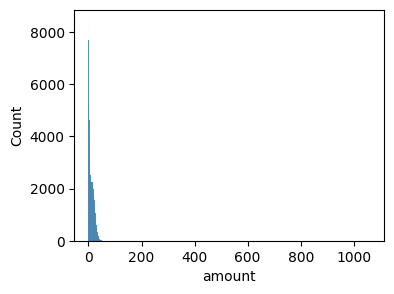

In [110]:
# Revisamos outliers
plt.figure(figsize=(4, 3))
sns.histplot(data=events_final, x='amount')

In [209]:
# Outliers en amount
print(events_final[events_final['amount'] > 300].head())
print(events_final['amount'].max())

                            customer_id        event  time  amount  reward  \
18053  8a776d222f174aa089866b2725721eec  transaction     6  448.97     NaN   
18800  04f1f44632cd409cace939fa62b5fc7a  transaction    12  628.41     NaN   
19097  a12fba072dae4e3aae2e1b4b92b92aa1  transaction    12  871.51     NaN   
19845  f1d65ae63f174b8f80fa063adcaa63b7  transaction    12  639.59     NaN   
20529  d820adac939d46078131f147d99d3f85  transaction    18  656.46     NaN   

      offer_id  
18053      NaN  
18800      NaN  
19097      NaN  
19845      NaN  
20529      NaN  
1062.28


In [215]:
# A lo mejor si que son outliers -> en este caso la forma de gestionarlos puede tener que ver con hablar con negocio
events_final[(events_final['customer_id'] == '8a776d222f174aa089866b2725721eec') & (~events_final['amount'].isnull())].head()

,customer_id,event,time,amount,reward,offer_id
18053,8a776d222f174aa089866b2725721eec,transaction,6,448.97,NaN,NaN
20265,8a776d222f174aa089866b2725721eec,transaction,12,16.49,NaN,NaN
24207,8a776d222f174aa089866b2725721eec,transaction,24,17.71,NaN,NaN
26104,8a776d222f174aa089866b2725721eec,transaction,30,18.31,NaN,NaN
34033,8a776d222f174aa089866b2725721eec,transaction,60,16.53,NaN,NaN


In [221]:
# Calculate the 99th percentile for the 'amount' column
percentile_99 = events_final['amount'].quantile(0.99)
print(percentile_99)

print("Total len: ", len(events_final), "; Len without outliers: ", len(events_final[events_final['amount'] < percentile_99]))
print("Percentage: ", (len(events_final[events_final['amount'] < percentile_99])/len(events_final))*100)


40.01960000000021
Total len:  306534 ; Len without outliers:  137563
Percentage:  44.876914143292424


<Axes: xlabel='amount', ylabel='Count'>

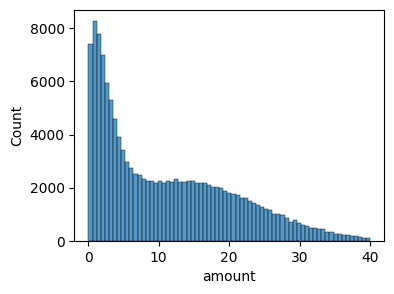

In [217]:
plt.figure(figsize=(4, 3))
sns.histplot(data=events_final[events_final['amount'] < percentile_99], x='amount')

# 3. Analisis de los datos
## 3.1 KPIs totales
Ejemplos: 
- Total Transactions: 138,953
- Total Unique Clients: 16,578
- Total Income: 1,775,451$ -> 1.78M$
- Total de ofertas mandadas:
- Total de ofertas vistas:
- Total de ofertas completadas:

#### Total de transacciones y clientes

In [174]:
#Número de clientes diferentes que compraron en ese rango de fechas
transactions = events_final[events_final['event'] == 'transaction']
print('N transacciones: ', len(transactions))
print('N de clientes diferentes: ', transactions['customer_id'].nunique())
print(transactions['customer_id'].value_counts())

N transacciones:  138953
N de clientes diferentes:  16578
customer_id
79d9d4f86aca4bed9290350fb43817c2    36
8dbfa485249f409aa223a2130f40634a    36
94de646f7b6041228ca7dec82adb97d2    35
b1f4ece7d49342628a9ed77aee2cde58    32
5e60c6aa3b834e44b822ea43a3efea26    32
                                    ..
dec84283d63e4e69809ed531f9e19b3a     1
59d01620b8c04fdbb630040c6deeb0a1     1
f47de7e07e1149429d604937326ae500     1
839649618a584369a51d594acbd1e80d     1
0c027f5f34dd4b9eba0a25785c611273     1
Name: count, Length: 16578, dtype: int64


In [138]:
#Agrupo para saber cuantas transacciones realizó cada cliente en ese intervalo de tiempo
transactions_by_client = transactions.groupby('customer_id').size().reset_index(name='number_transactions').sort_values(by='number_transactions', ascending=False)
transactions_by_client.head()


,customer_id,number_transactions
7887,79d9d4f86aca4bed9290350fb43817c2,36
9239,8dbfa485249f409aa223a2130f40634a,36
9702,94de646f7b6041228ca7dec82adb97d2,35
11652,b1f4ece7d49342628a9ed77aee2cde58,32
6118,5e60c6aa3b834e44b822ea43a3efea26,32


<Axes: xlabel='number_transactions', ylabel='Count'>

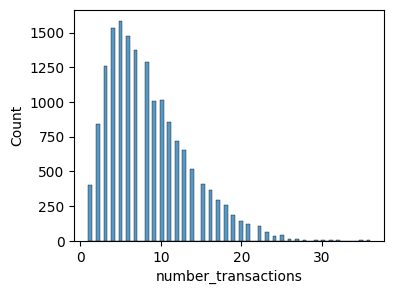

In [ ]:
#Lo visualizamos
plt.figure(figsize=(4,3))
sns.histplot(data=transactions_by_client, x='number_transactions')

In [142]:
# Puedo hacer diferentes grupos basandonos en la cantidad de transaciones, para así poder targetearlos directamente
non_returning_clients = transactions_by_client[transactions_by_client['number_transactions'] == 1]
returning_clients = transactions_by_client[(transactions_by_client['number_transactions'] > 1) & (transactions_by_client['number_transactions'] <= 15)]
top_clients = transactions_by_client[transactions_by_client['number_transactions'] > 15]

In [153]:
#Pregunta: cuál es el gasto medio de  los top clients?
top_clients_purchase = events_final[(events_final['customer_id'].isin(top_clients['customer_id'])) & (events_final['event'] == 'transaction')]['amount']
top_clients_purchase.head()

12686     0.22
12743    13.57
12768     4.20
12785    14.27
12861    19.82
Name: amount, dtype: float64

In [160]:
#Cuál es la media de compra de estos top clients? -> 8.28$
top_clients_purchase.mean()

np.float64(8.287175641025641)

In [161]:
#¿Cuál es la media de compra de los returning clients? -> 14.08
events_final[(events_final['customer_id'].isin(returning_clients['customer_id'])) & (events_final['event'] == 'transaction')]['amount'].mean()

np.float64(14.080014717937255)

In [162]:
#¿Y la de los que solo han comprado una vez?
events_final[(events_final['customer_id'].isin(non_returning_clients['customer_id'])) & (events_final['event'] == 'transaction')]['amount'].mean()

np.float64(13.402369077306734)

#### Total de ingresos

In [175]:
#### Total de ingresos['amount'].sum()

np.float64(1775451.9700000004)

#### Funnel de ofertas recibidas, vistas y completadas

In [180]:
offers_funnel = events_final[events_final['event'] != 'transaction']['event'].value_counts().reset_index(name='count')
offers_funnel

,event,count
0,offer received,76277
1,offer viewed,57725
2,offer completed,33579


In [185]:
offers_funnel['percentage_drop'] = 100.0

In [186]:
for i in range(1, len(offers_funnel)):
    offers_funnel.loc[i, 'percentage_drop'] = (offers_funnel.loc[i, 'count'] / offers_funnel.loc[i-1, 'count']) *100
offers_funnel

,event,count,percentage_drop
0,offer received,76277,100.000000
1,offer viewed,57725,75.678121
2,offer completed,33579,58.170637


In [187]:
# Redondeamos los valores a dos decimales para mejor visualización
offers_funnel['percentage_drop'] = offers_funnel['percentage_drop'].round(2)

offers_funnel

,event,count,percentage_drop
0,offer received,76277,100.00
1,offer viewed,57725,75.68
2,offer completed,33579,58.17


Conclusión: hay una tasa de visita de la oferta bastante alta, aunque la conversión a completada es de solo el 60%.

### Análisis de clientes por loyalty (desde cuando son miembros)

In [224]:
customers_cleaned.columns

Index(['customer_id', 'became_member_on', 'gender', 'age', 'income'], dtype='object')

In [233]:
# Vamos a hacer un conteo de clientes POR MES
# Create a new column for year-month
customers_cleaned['year_month'] = customers_cleaned['became_member_on'].dt.to_period('M')

# Group by year-month and count the number of customers for each month
customers_by_month = customers_cleaned.groupby('year_month').size().reset_index(name='customer_count').sort_values(by='year_month')

In [234]:
print(customers_by_month.info())
customers_by_month.tail(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61 entries, 0 to 60
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype    
---  ------          --------------  -----    
 0   year_month      61 non-null     period[M]
 1   customer_count  61 non-null     int64    
dtypes: int64(1), period[M](1)
memory usage: 1.1 KB
None


,year_month,customer_count
51,2017-10,900
52,2017-11,816
53,2017-12,900
54,2018-01,809
55,2018-02,517
56,2018-03,618
57,2018-04,585
58,2018-05,601
59,2018-06,562
60,2018-07,506


In [229]:
customers_by_month.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61 entries, 0 to 60
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype    
---  ------          --------------  -----    
 0   year_month      61 non-null     period[M]
 1   customer_count  61 non-null     int64    
dtypes: int64(1), period[M](1)
memory usage: 1.1 KB


In [230]:
# Convertimos year month a string para poder hacer el plot
customers_by_month['year_month'] = customers_by_month['year_month'].astype(str)

<Axes: xlabel='year_month', ylabel='customer_count'>

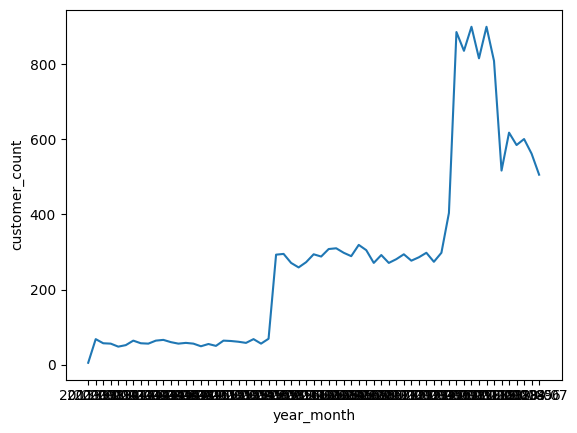

In [231]:
#plt.figure(figsize=(4,3))
sns.lineplot(data=customers_by_month, x='year_month', y='customer_count')

### Análisis bivariado: ¿hay alguna relación entre el "amount" y el "income"?

Text(0.5, 1.0, 'Scatter Plot')

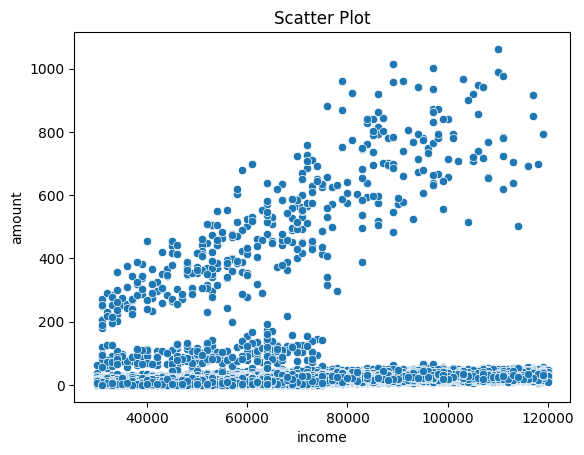

In [243]:
# Scatter plot using seaborn:
sns.scatterplot(data=events_with_customer_info, x='income', y='amount')
plt.title('Scatter Plot')